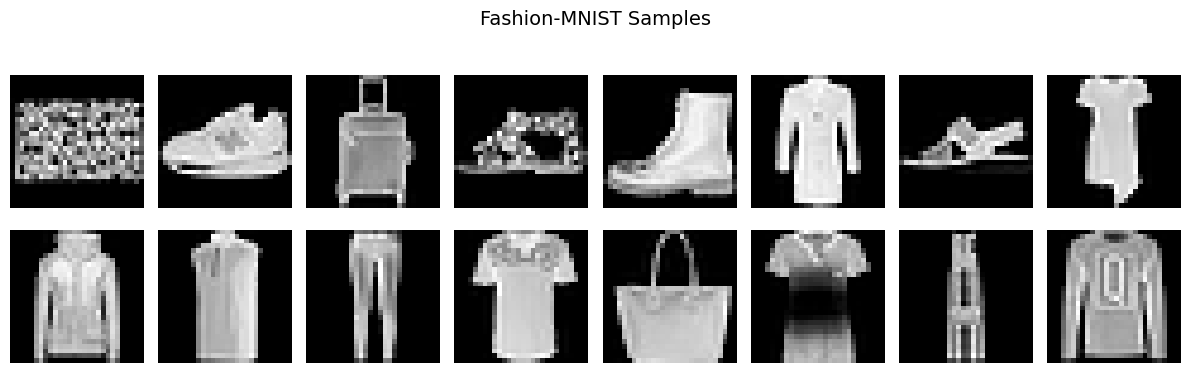

In [10]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.ToTensor()
])

import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn.functional as F

transform = transforms.Compose([
    transforms.ToTensor()
])

target_transform = transforms.Lambda(
    lambda y: F.one_hot(torch.tensor(y), num_classes=10).float()
)

trainset = torchvision.datasets.FashionMNIST(
    root='./data', 
    train=True, 
    download=True, 
    transform=transform,
    target_transform=target_transform
)

testset = torchvision.datasets.FashionMNIST(
    root='./data', 
    train=False, 
    download=True, 
    transform=transform,
    target_transform=target_transform
)

train_loader = torch.utils.data.DataLoader(
    trainset, 
    batch_size=64, 
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    testset, 
    batch_size=64, 
    shuffle=False
)

classes = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

import matplotlib.pyplot as plt

dataiter = iter(train_loader)
images, labels = next(dataiter)

fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for idx, ax in enumerate(axes.flat):
    ax.imshow(images[idx].squeeze(), cmap='gray')
    ax.axis('off')
    # ax.set_title(classes[labels[idx]], fontsize=9)

plt.suptitle("Fashion-MNIST Samples", fontsize=14)
plt.tight_layout()
plt.show()


In [12]:
labels.shape

torch.Size([64, 10])

In [56]:
import torch.nn as nn

class VAE(nn.Module):
    def __init__(self):

        super().__init__()
        
        self.encoder = nn.Sequential(
            nn.Linear(784 + 10 , 400),
            nn.ReLU()
        )

        self.mu = nn.Linear(400,2)
        self.logvar = nn.Linear(400,2)

        self.decoder = nn.Sequential(
            nn.Linear(12 , 400),
            nn.ReLU(),
            nn.Linear(400 , 784 ),
        )

    def forward(self , x , y):
        inp = torch.concat([x , y] , dim = 1)
        encoder = self.encoder(inp)

        mu = self.mu(encoder)
        logvar = self.logvar(encoder)

        eps = torch.randn_like(logvar)

        std = torch.exp(0.5 * logvar)
        
        z = mu + eps * std
    
        latent = torch.concat([z , y] , dim = 1)
        recon = self.decoder(latent)

        return mu , logvar , recon 
    

model = VAE()

In [57]:
import torch.nn.functional as F

def loss_fn(mu , logvar , x , x_recon):

    recon_loss = F.binary_cross_entropy_with_logits(input=x_recon , target=x , reduction='sum')
    
    kl_loss = -0.5 * torch.sum((logvar + 1 - mu ** 2 - torch.exp(logvar)))

    return (recon_loss + kl_loss) / x.size(0)
    

In [58]:
learning_rate = 0.01

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [59]:
batch_size  = 64

def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X = X.reshape(-1 , 784)
        
        mu , logvar , recon = model(X , y)
        loss = loss_fn(mu , logvar , X , recon)


        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


def test_loop(dataloader, model, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss = 0

    with torch.no_grad():
        for X, y in dataloader:
            X = X.reshape(-1 , 784)
            mu , logvar , recon = model(X , y)
            test_loss += loss_fn(mu , logvar , X , recon)
            
    test_loss /= num_batches
    print(f"Avg loss: {test_loss:>8f} \n")

In [60]:
for t in range(5):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, optimizer)
    test_loop(test_loader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 545.741821  [   64/60000]
loss: 266.087494  [ 6464/60000]
loss: 263.227386  [12864/60000]
loss: 282.983521  [19264/60000]
loss: 252.092651  [25664/60000]
loss: 249.968506  [32064/60000]
loss: 273.465271  [38464/60000]
loss: 281.725830  [44864/60000]
loss: 247.793991  [51264/60000]
loss: 246.730484  [57664/60000]
Epoch 2
-------------------------------
loss: 252.016602  [   64/60000]
loss: 238.710205  [ 6464/60000]
loss: 252.621399  [12864/60000]
loss: 289.859528  [19264/60000]
loss: 242.730179  [25664/60000]
loss: 259.436432  [32064/60000]
loss: 264.167572  [38464/60000]
loss: 251.906357  [44864/60000]
loss: 241.452423  [51264/60000]
loss: 269.149506  [57664/60000]
Epoch 3
-------------------------------
loss: 241.030930  [   64/60000]
loss: 259.495392  [ 6464/60000]
loss: 247.015533  [12864/60000]
loss: 252.536484  [19264/60000]
loss: 243.840179  [25664/60000]
loss: 279.772125  [32064/60000]
loss: 267.592102  [38464/60000]
loss: 251.973984

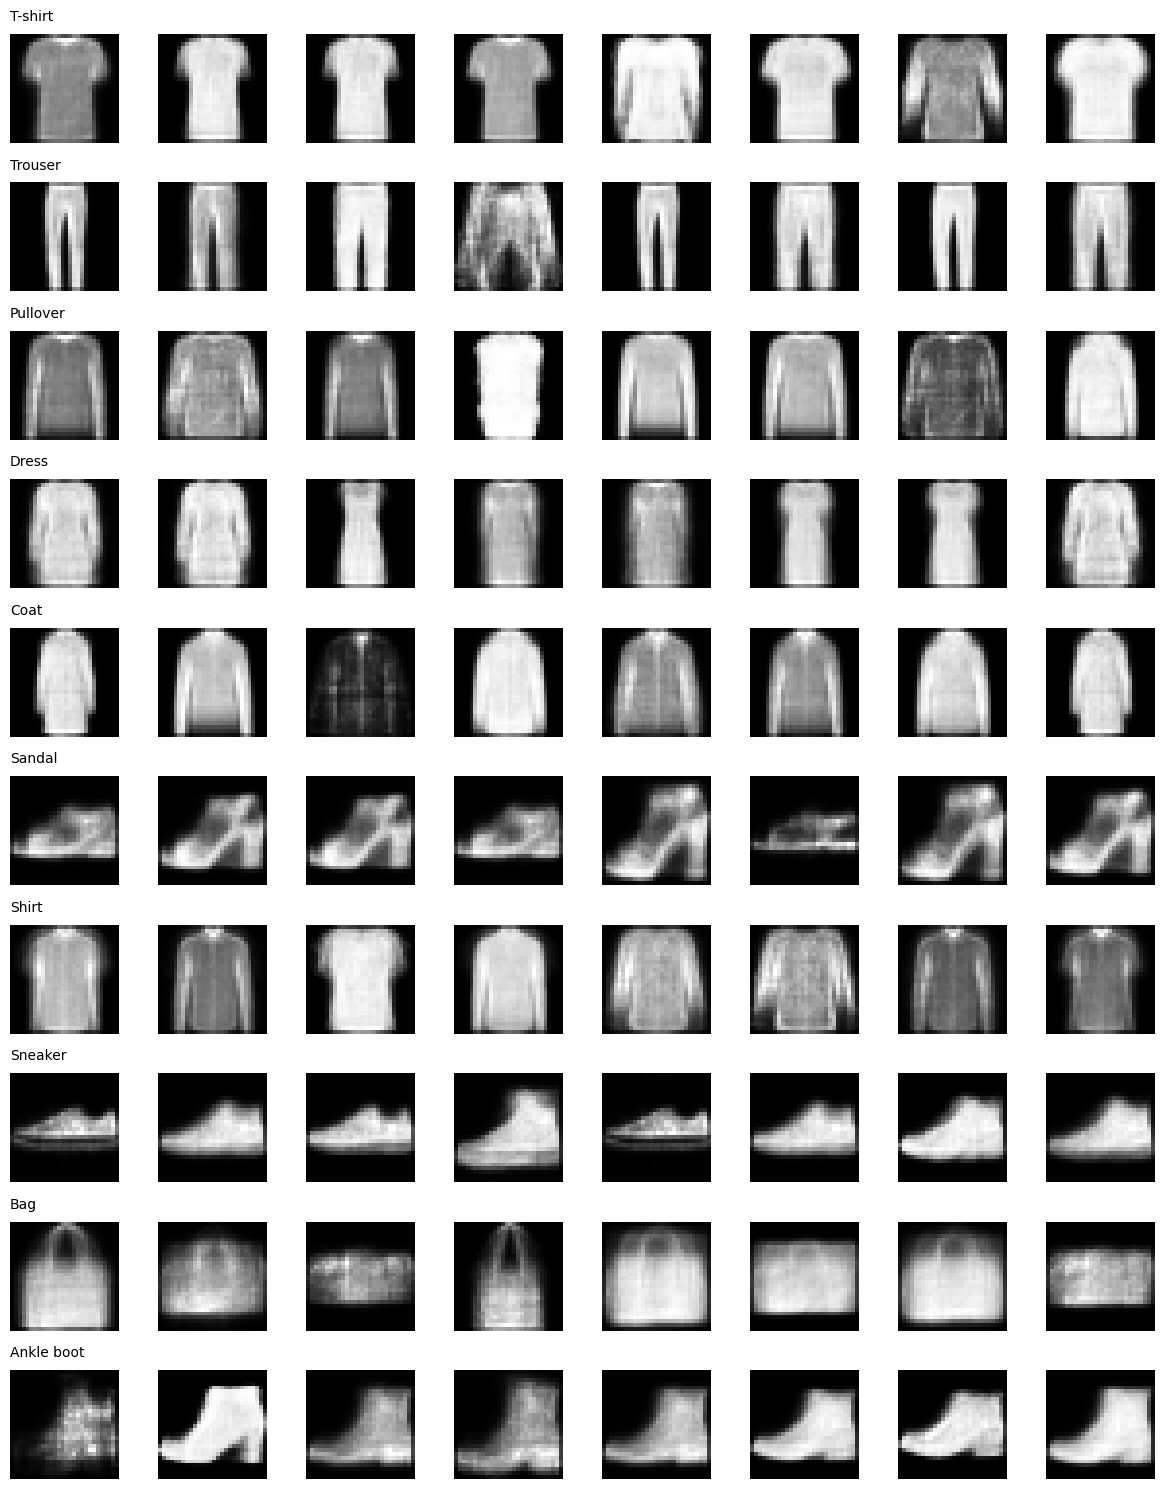

In [64]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

classes = [
    'T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

def generate_conditional_samples(model, num_samples_per_class=8, latent_dim=2):
    model.eval()
    num_classes = 10
    
    fig, axes = plt.subplots(num_classes, num_samples_per_class, figsize=(num_samples_per_class * 1.5, num_classes * 1.5))
    
    with torch.no_grad():
        for c in range(num_classes):
            z = torch.randn(num_samples_per_class, latent_dim)
            
            label_idx = torch.full((num_samples_per_class,), fill_value=c, dtype=torch.long)
            y_onehot = F.one_hot(label_idx, num_classes=num_classes).float()
            
            latent_input = torch.cat([z, y_onehot], dim=1)
            
            recon_logits = model.decoder(latent_input)
            generated_images = torch.sigmoid(recon_logits).view(-1, 28, 28).cpu().numpy()
            
            for i in range(num_samples_per_class):
                ax = axes[c, i]
                ax.imshow(generated_images[i], cmap='gray')
                ax.axis('off')
                if i == 0:
                    ax.set_title(classes[c], fontsize=10, loc='left', pad=10)


    plt.tight_layout()
    plt.show()

generate_conditional_samples(model, num_samples_per_class=8, latent_dim=2)


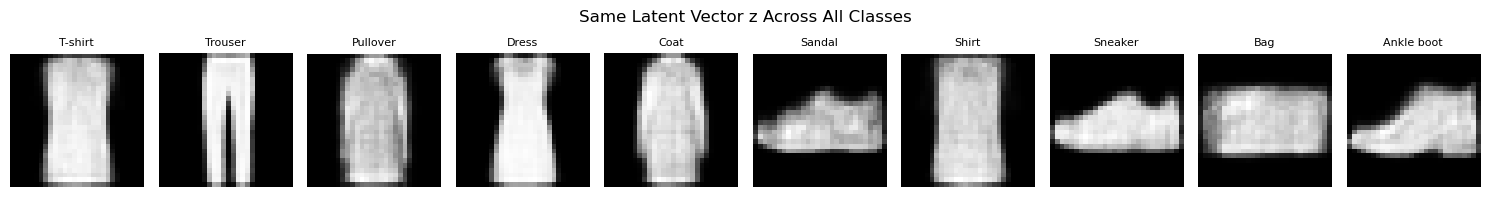

In [65]:
def generate_fixed_style_across_classes(model, latent_dim=2):
    model.eval()
    
    fixed_z = torch.randn(1, latent_dim).repeat(10, 1)  # ابعاد [10, 2]
    
    labels = torch.arange(10)
    y_onehot = F.one_hot(labels, num_classes=10).float()
    
    with torch.no_grad():
        latent_input = torch.cat([fixed_z, y_onehot], dim=1)
        recon_logits = model.decoder(latent_input)
        generated_images = torch.sigmoid(recon_logits).view(10, 28, 28).cpu().numpy()
        
    fig, axes = plt.subplots(1, 10, figsize=(15, 2))
    for i in range(10):
        axes[i].imshow(generated_images[i], cmap='gray')
        axes[i].set_title(classes[i], fontsize=8)
        axes[i].axis('off')
        
    plt.suptitle("Same Latent Vector z Across All Classes", fontsize=12)
    plt.tight_layout()
    plt.show()

generate_fixed_style_across_classes(model, latent_dim=2)
